In [20]:
!pip install numpy
!pip install matplotlib
!pip install pandas
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


In [21]:
import pandas as pd

# x is positive in downward direction 
# y is positive onshore direction 
# z is postive direction of port

cols = [
    "burst",        # Burst counter
    "ensemble",     # Ensemble counter (1-65536)
    "x",            # x is positive in downward direction 
    "y",            # y is positive onshore direction 
    "z",            #  z is postive direction of port
    "amp1",         # Amplitude Beam1 (counts)
    "amp2",         # Amplitude Beam2 (counts)
    "amp3",         # Amplitude Beam3 (counts)
    "snr1",         # SNR Beam1 (dB)
    "snr2",         # SNR Beam2 (dB)
    "snr3",         # SNR Beam3 (dB)
    "corr1",        # Correlation Beam1 (%)
    "corr2",        # Correlation Beam2 (%)
    "corr3",        # Correlation Beam3 (%)
    "pressure",     # Pressure (dbar)
    "OBS",      # Analog input 1
    "analog2",      # Analog input 2
    "checksum",     # Checksum (1 = failed)
]



df = pd.read_csv("SSC01.dat", sep=r"\s+", header=None, names=cols)

In [22]:
df["t"] = df.index / 16
start = pd.Timestamp("2026-09-29 06:00:00")
df["time"] = start + pd.to_timedelta(df["t"], unit="s")

In [23]:
DAY = start.strftime("%Y-%m-%d")
MEASUREMENT_DAY = 1   # 1 = series 1-4 (A1-11 ... F-41), 2 = series 5+ (B1-51 ... B3-81)

def load_manoeuvres(path="manoeuvresTimes.csv", day=None):
    m = pd.read_csv(path, dtype=str)
    series = m["id"].str.split("-").str[1].str[0].astype(int)
    if day == 1:
        m = m[series <= 4]
    elif day == 2:
        m = m[series >= 5]
    return {row.id: (row.times.split(";") if ";" in row.times else row.times)
            for row in m.itertuples()}

manoeuvres = load_manoeuvres(day=MEASUREMENT_DAY)
print(f"{len(manoeuvres)} manoeuvres loaded for day {MEASUREMENT_DAY}")


44 manoeuvres loaded for day 1


In [24]:
import matplotlib.dates as mdates



def to_x(t, t_start, seconds):
    """Convert time(s) to x-axis values: timestamps, or seconds since t_start."""
    if not seconds:
        return t
    if isinstance(t, pd.Series):
        return (t - t_start).dt.total_seconds()
    return (t - t_start).total_seconds()

def plot_uvw(data, start, end, seconds=False):
    t_start = pd.Timestamp(f"{DAY} {start}")
    t_end   = pd.Timestamp(f"{DAY} {end}")

    part = data[(data["time"] >= t_start) & (data["time"] <= t_end)].copy()

    

    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for ax, comp in zip(axes, ["corr1", "corr2", "corr3"]):
        ax.plot(to_x(part["time"], t_start, seconds), part[comp], lw=0.5, color="#0033cc", label="raw")
        ax.set_ylabel(comp)
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel(f"Time since {start} (s)" if seconds else "Time (HH:MM)")

    for name, t in manoeuvres.items():
        if isinstance(t, str):
            t = [t]
        xs = [pd.Timestamp(f"{DAY} {x}") for x in t]
        xs = [x for x in xs if t_start <= x <= t_end]
        if not xs:
            continue
        for x in xs:
            for ax in axes:
                ax.axvline(to_x(x, t_start, seconds), color="k", ls="--", lw=0.6)
        mid = to_x(xs[0] + (xs[-1] - xs[0]) / 2, t_start, seconds)
        axes[0].text(mid, 1.01, name, transform=axes[0].get_xaxis_transform(),
                     rotation=90, ha="center", va="bottom", fontsize=13, fontweight="bold",
                     color="darkred", bbox=dict(boxstyle="round,pad=0.2", fc="lightyellow", ec="darkred", lw=0.8))

    axes[-1].set_xlim(to_x(t_start, t_start, seconds), to_x(t_end, t_start, seconds))
    if not seconds:
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.tight_layout()
    plt.show()

In [25]:
def plot_sediment(comp, start, end, seconds=False):
    t_start = pd.Timestamp(f"{DAY} {start}")
    t_end   = pd.Timestamp(f"{DAY} {end}")

    data = df
    part = data[(data["time"] >= t_start) & (data["time"] <= t_end)].copy()

    
    

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(to_x(part["time"], t_start, seconds), part[comp], lw=0.5, color="#0033cc", label="raw")
    if comp == "OBS":
        label = "(mV)"
    else:
        label = "m/s"
    ax.set_ylabel(f"{comp} {label}")
    ax.set_xlabel(f"Time since {start} (s)" if seconds else "Time (HH:MM)")
    ax.grid(True, alpha=0.3)

    for name, t in manoeuvres.items():
        if isinstance(t, str):
            t = [t]
        xs = [pd.Timestamp(f"{DAY} {x}") for x in t]
        xs = [x for x in xs if t_start <= x <= t_end]
        if not xs:
            continue
        for x in xs:
            ax.axvline(to_x(x, t_start, seconds), color="k", ls="--", lw=0.6)
        mid = to_x(xs[0] + (xs[-1] - xs[0]) / 2, t_start, seconds)
        ax.text(mid, 0.93, name, transform=ax.get_xaxis_transform(),
                rotation=0, ha="center", va="bottom", fontsize=13, fontweight="bold",
                     color="black", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black", lw=0.8))

    ax.set_xlim(to_x(t_start, t_start, seconds), to_x(t_end, t_start, seconds))
    if not seconds:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.tight_layout()
    plt.show()

Manoeuvre C

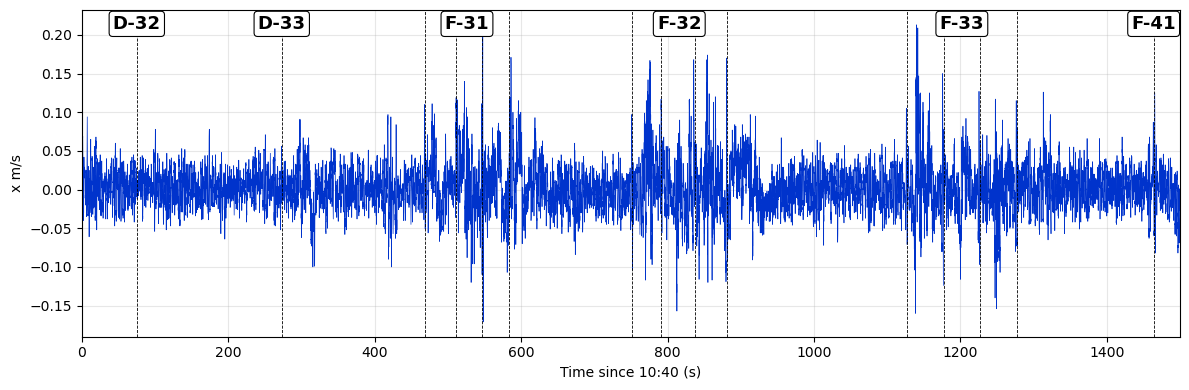

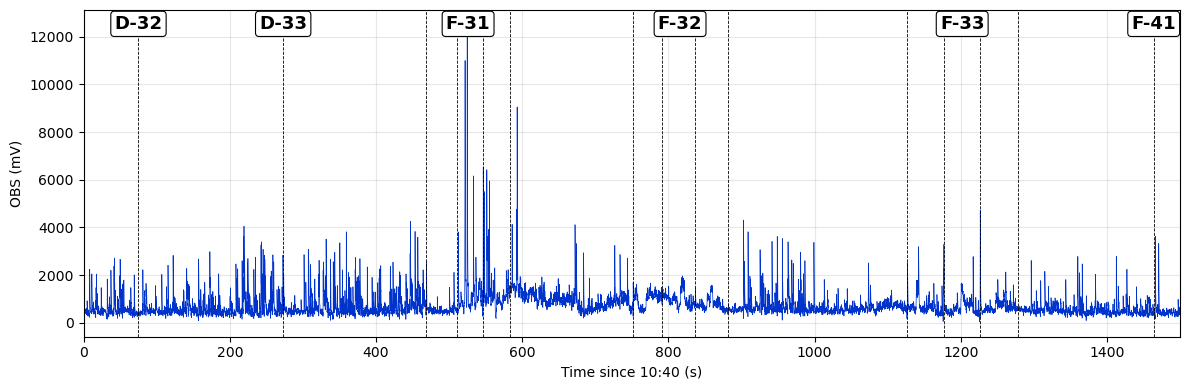

In [26]:
# x is positive in downward direction 
# y is positive onshore direction 
# z is postive direction of port
plot_sediment("x", "10:40", "11:05",seconds=True)  # no filtering
plot_sediment("OBS", "10:40", "11:05",seconds=True)  # no filtering

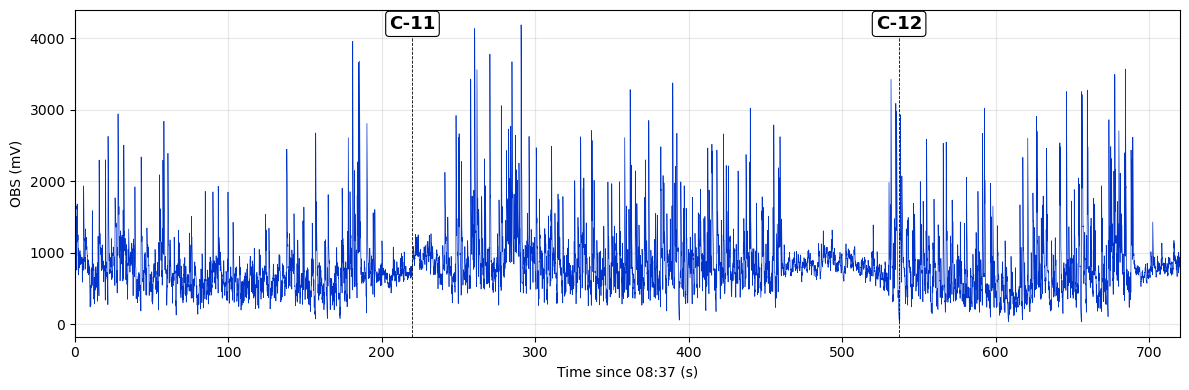

In [29]:


plot_sediment("OBS", "08:37", "08:49", seconds = True)  # no filtering

In [28]:

plot_sediment("z", "10:50", "10:53", filter_peaks=False,seconds=True)  # no filtering

TypeError: plot_sediment() got an unexpected keyword argument 'filter_peaks'

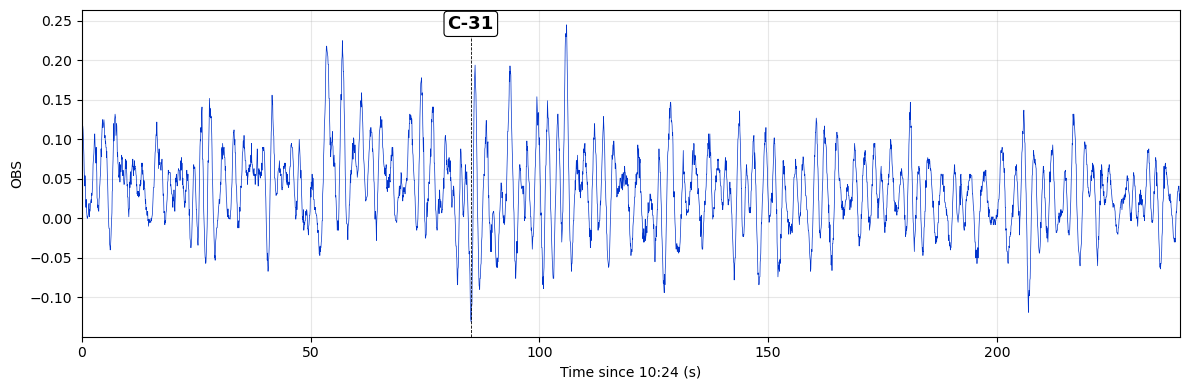

In [ ]:
plot_sediment("y", "10:24", "10:28", filter_peaks=False, seconds=True)  # no filtering

KeyError: 'w'

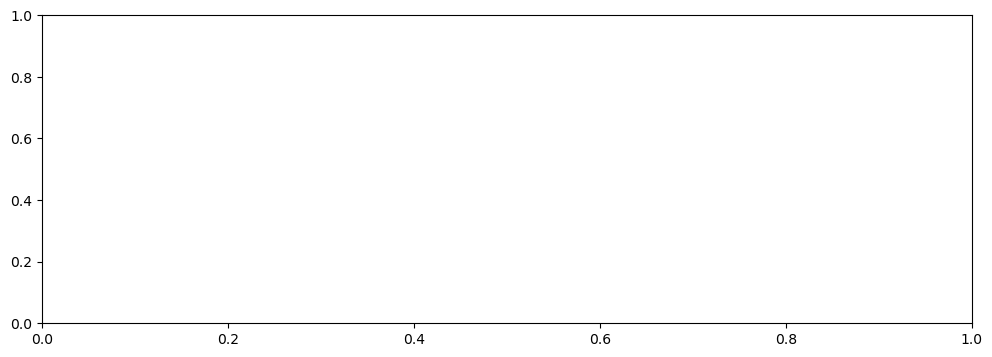

In [ ]:
plot_sediment("w", "08:37", "08:49", filter_peaks=False, seconds=True)  # no filtering

Manoeuvre D

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=cb8feeb3-afee-4b20-ab89-f0abd9348b44' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>